In [ ]:

import pandas as pd
import re
from google.colab import files

# Upload:
# 1. glofas_garissa_final.csv
# 2. chirps_garissa_2000_2025.csv



In [ ]:
uploaded = files.upload()

glofas_file = next(
    (f for f in uploaded if "glofas" in f.lower()), None
)
chirps_file = next(
    (f for f in uploaded if "chirps" in f.lower()), None
)

if not glofas_file or not chirps_file:
    raise ValueError(
        "Please upload both the GloFAS and CHIRPS CSV files."
    )

discharge = pd.read_csv(glofas_file)
rainfall = pd.read_csv(chirps_file)

def audit(name, df):
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)
    print("Shape:", df.shape)
    print("\nColumns:", df.columns.tolist())
    print("\nData types:\n", df.dtypes)
    print("\nFirst five rows:\n", df.head())
    print("\nMissing values:\n", df.isna().sum())
    print("\nDuplicate rows:", df.duplicated().sum())

audit("GloFAS DISCHARGE", discharge)
audit("CHIRPS RAINFALL", rainfall)

# Identify likely date columns without assuming exact names.
def find_date_column(df):
    for col in df.columns:
        name = re.sub(r"[^a-z]", "", col.lower())
        if name in {"date", "datetime", "time", "timestamp"}:
            return col
    return None

glofas_date = find_date_column(discharge)
chirps_date = find_date_column(rainfall)

print("\nDATE COLUMN CHECK")
print("GloFAS:", glofas_date)
print("CHIRPS:", chirps_date)

if glofas_date and chirps_date:
    discharge[glofas_date] = pd.to_datetime(
        discharge[glofas_date], errors="coerce"
    ).dt.normalize()

    rainfall[chirps_date] = pd.to_datetime(
        rainfall[chirps_date], errors="coerce"
    ).dt.normalize()

    print("\nGloFAS date range:",
          discharge[glofas_date].min(),
          "to", discharge[glofas_date].max())

    print("CHIRPS date range:",
          rainfall[chirps_date].min(),
          "to", rainfall[chirps_date].max())

    print("Invalid GloFAS dates:",
          discharge[glofas_date].isna().sum())

    print("Invalid CHIRPS dates:",
          rainfall[chirps_date].isna().sum())

    print("Duplicate GloFAS dates:",
          discharge[glofas_date].duplicated().sum())

    print("Duplicate CHIRPS dates:",
          rainfall[chirps_date].duplicated().sum())

    g_dates = set(discharge[glofas_date].dropna())
    r_dates = set(rainfall[chirps_date].dropna())
    overlap = g_dates & r_dates

    print("\nUnique GloFAS dates:", len(g_dates))
    print("Unique CHIRPS dates:", len(r_dates))
    print("Overlapping dates:", len(overlap))

    if overlap:
        print("Overlap range:", min(overlap), "to", max(overlap))
else:
    print(
        "\nDate columns were not identified automatically. "
        "Inspect the column names above before merging."
    )

Saving chirps_garissa_2000_2025.csv to chirps_garissa_2000_2025.csv
Saving glofas_garissa_final.csv to glofas_garissa_final.csv

GloFAS DISCHARGE
Shape: (9587, 2)

Columns: ['date', 'discharge_m3s']

Data types:
 date              object
discharge_m3s    float64
dtype: object

First five rows:
          date  discharge_m3s
0  2000-01-01      164.65625
1  2000-01-02      158.85938
2  2000-01-03      150.79688
3  2000-01-04      142.56250
4  2000-01-05      135.39062

Missing values:
 date             0
discharge_m3s    0
dtype: int64

Duplicate rows: 0

CHIRPS RAINFALL
Shape: (9497, 4)

Columns: ['system:index', 'date', 'rainfall_mm', '.geo']

Data types:
 system:index      int64
date             object
rainfall_mm     float64
.geo             object
dtype: object

First five rows:
    system:index        date  rainfall_mm  \
0      20000101  2000-01-01     0.031244   
1      20000102  2000-01-02     0.625716   
2      20000103  2000-01-03     0.064589   
3      20000104  2000-01-04    

Combined dataset shape: (9497, 3)
Date range: 2000-01-01 00:00:00 to 2025-12-31 00:00:00
Missing values:
 date             0
discharge_m3s    0
rainfall_mm      0
dtype: int64

Summary statistics:
        discharge_m3s  rainfall_mm
count    9497.000000  9497.000000
mean      188.035436     0.917235
std       194.867077     3.326457
min         6.343750     0.000000
25%        74.921875     0.000000
50%       128.890620     0.014938
75%       233.500000     0.313457
max      2656.296900    68.502357

Saved: /content/garissa_master_dataset.csv


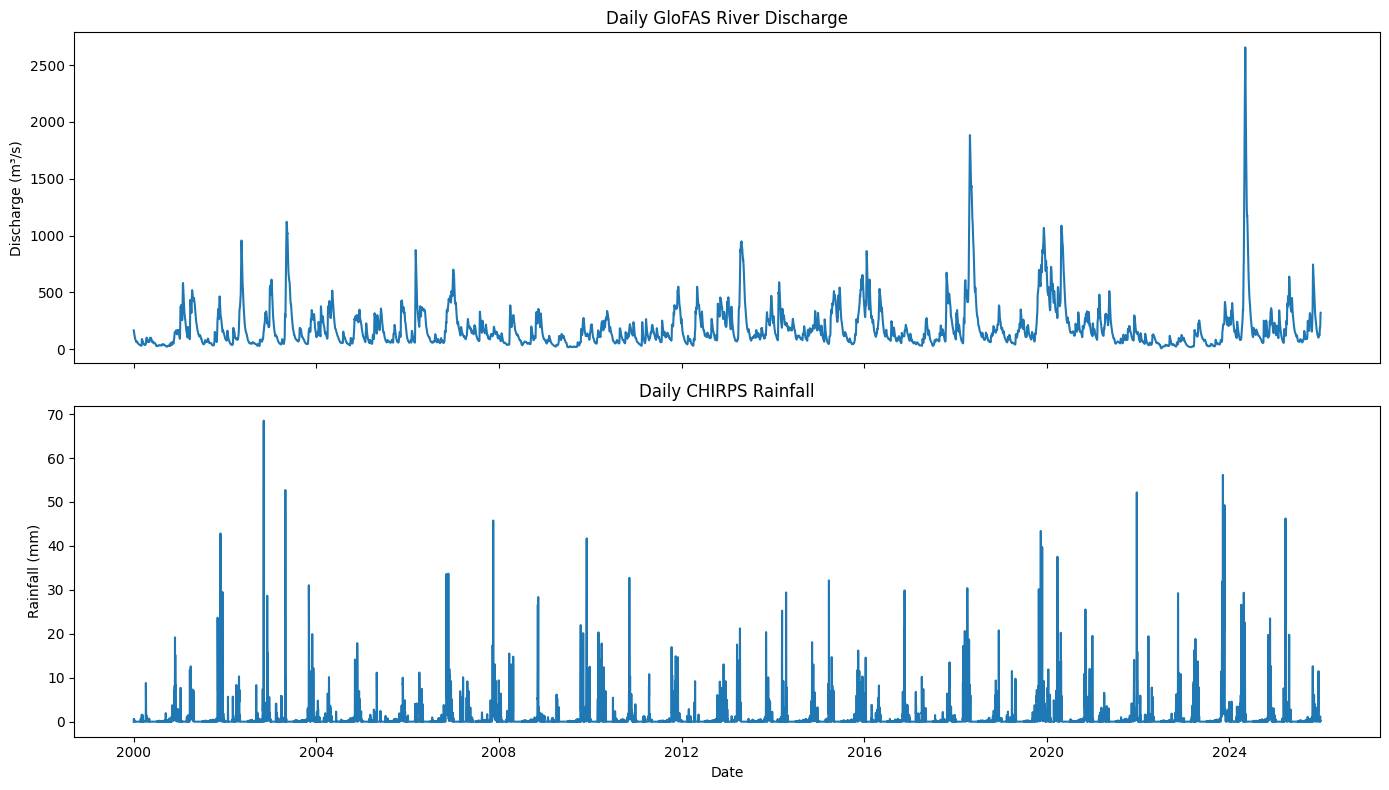

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Keep only the columns needed for modelling.
glofas_clean = discharge[["date", "discharge_m3s"]].copy()
chirps_clean = rainfall[["date", "rainfall_mm"]].copy()

# 2. Standardise dates and numeric values.
glofas_clean["date"] = pd.to_datetime(
    glofas_clean["date"], errors="coerce"
).dt.normalize()

chirps_clean["date"] = pd.to_datetime(
    chirps_clean["date"], errors="coerce"
).dt.normalize()

glofas_clean["discharge_m3s"] = pd.to_numeric(
    glofas_clean["discharge_m3s"], errors="coerce"
)
chirps_clean["rainfall_mm"] = pd.to_numeric(
    chirps_clean["rainfall_mm"], errors="coerce"
)

# 3. Stop if dates or values are invalid.
assert glofas_clean["date"].notna().all(), "Invalid GloFAS dates"
assert chirps_clean["date"].notna().all(), "Invalid CHIRPS dates"

assert glofas_clean["date"].is_unique, "Duplicate GloFAS dates"
assert chirps_clean["date"].is_unique, "Duplicate CHIRPS dates"

assert glofas_clean["discharge_m3s"].notna().all()
assert chirps_clean["rainfall_mm"].notna().all()

assert (glofas_clean["discharge_m3s"] >= 0).all(), \
    "Negative discharge detected"

assert (chirps_clean["rainfall_mm"] >= 0).all(), \
    "Negative rainfall detected"

# 4. Merge only dates available in both datasets.
master = pd.merge(
    glofas_clean,
    chirps_clean,
    on="date",
    how="inner",
    validate="one_to_one"
).sort_values("date").reset_index(drop=True)

# 5. Validate the result.
print("Combined dataset shape:", master.shape)
print("Date range:", master["date"].min(), "to", master["date"].max())
print("Missing values:\n", master.isna().sum())
print("\nSummary statistics:\n", master[
    ["discharge_m3s", "rainfall_mm"]
].describe())

assert len(master) == 9497, "Unexpected merged row count"
assert master["date"].is_unique
assert master.isna().sum().sum() == 0

# 6. Save the master dataset.
output_file = "/content/garissa_master_dataset.csv"
master.to_csv(output_file, index=False)
print("\nSaved:", output_file)

# 7. Inspect distributions and trends.
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(master["date"], master["discharge_m3s"])
axes[0].set_title("Daily GloFAS River Discharge")
axes[0].set_ylabel("Discharge (m³/s)")

axes[1].plot(master["date"], master["rainfall_mm"])
axes[1].set_title("Daily CHIRPS Rainfall")
axes[1].set_ylabel("Rainfall (mm)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# Ensure dates are in datetime format
master["date"] = pd.to_datetime(master["date"])
master = master.sort_values("date").reset_index(drop=True)

# Find the 20 days with the highest river discharge
top_flow_days = master.nlargest(20, "discharge_m3s").copy()

# Add rainfall from the same day and previous 1, 3, and 7 days
for days in [1, 3, 7]:
    master[f"rainfall_previous_{days}d"] = (
        master["rainfall_mm"]
        .rolling(window=days, min_periods=days)
        .sum()
    )

top_flow_days = master.loc[
    top_flow_days.index,
    ["date", "discharge_m3s", "rainfall_mm",
     "rainfall_previous_1d", "rainfall_previous_3d",
     "rainfall_previous_7d"]
]

print("20 highest-discharge days:")
print(top_flow_days.to_string(index=False))

print("\nDischarge percentiles:")
print(master["discharge_m3s"].quantile(
    [0.90, 0.95, 0.98, 0.99]
))

20 highest-discharge days:
      date  discharge_m3s  rainfall_mm  rainfall_previous_1d  rainfall_previous_3d  rainfall_previous_7d
2024-05-07      2656.2969     1.122626              1.122626              8.018541             43.873427
2024-05-08      2569.2031     1.738004              1.738004              3.353906             44.964200
2024-05-06      2548.5625     0.493275              0.493275             19.453735             42.815965
2024-05-05      2420.6250     6.402640              6.402640             41.512974             42.466422
2024-05-09      2412.0938     0.068095              0.068095              2.928725             44.934975
2024-05-04      2289.0781    12.557819             12.557819             35.207654             36.110895
2024-05-10      2252.7031     1.710675              1.710675              3.516775             24.093135
2024-05-03      2167.3750    22.552515             22.552515             23.297066             25.274513
2024-05-11      2118.2656   

In [ ]:
import pandas as pd

master = master.sort_values("date").reset_index(drop=True)

# Provisional threshold for exploratory analysis only
threshold = master["discharge_m3s"].quantile(0.95)

master["high_flow"] = (
    master["discharge_m3s"] >= threshold
).astype(int)

# Group consecutive high-flow days into episodes
master["episode_group"] = (
    master["high_flow"].diff().ne(0).cumsum()
)

episodes = (
    master[master["high_flow"] == 1]
    .groupby("episode_group")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        duration_days=("date", "size"),
        peak_discharge=("discharge_m3s", "max"),
        total_rainfall=("rainfall_mm", "sum")
    )
    .reset_index(drop=True)
    .sort_values("peak_discharge", ascending=False)
)

print(f"Exploratory 95th-percentile threshold: {threshold:.2f} m³/s")
print(f"High-flow days: {master['high_flow'].sum()}")
print(f"High-flow episodes: {len(episodes)}")
print("\nTop 15 episodes:")
print(episodes.head(15).to_string(index=False))

print("\nProportion of days classified as high flow:")
print(f"{master['high_flow'].mean() * 100:.2f}%")

Exploratory 95th-percentile threshold: 514.04 m³/s
High-flow days: 475
High-flow episodes: 32

Top 15 episodes:
start_date   end_date  duration_days  peak_discharge  total_rainfall
2024-04-22 2024-06-06             46      2656.29690       91.820694
2018-04-14 2018-06-04             52      1883.81250       98.500592
2003-05-01 2003-06-04             35      1120.68750       14.154228
2020-04-22 2020-05-22             31      1086.68750       69.322048
2019-10-25 2020-01-06             74      1067.14060      322.371942
2002-05-07 2002-05-23             17       956.00000        0.000000
2013-04-10 2013-05-18             39       948.68750       55.264077
2006-03-04 2006-03-13             10       871.78125        2.996156
2016-01-18 2016-02-01             15       862.93750        0.000000
2025-10-30 2025-11-08             10       744.82810       15.195909
2020-02-01 2020-02-18             18       724.26560        0.000000
2006-12-26 2007-01-10             16       699.81250        

In [ ]:

# STEP 1: Imports and setup
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    confusion_matrix
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# STEP 2: Prepare the chronological dataset
data = master[
    ["date", "discharge_m3s", "rainfall_mm"]
].copy()

data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date").reset_index(drop=True)

assert not data.isna().any().any(), "Missing values detected"
assert data["date"].is_unique, "Duplicate dates detected"

# Use the previous 30 days to predict the next day's discharge
LOOKBACK = 30
n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

print("Training period:", data.date.iloc[0].date(),
      "to", data.date.iloc[train_end - 1].date())
print("Validation period:", data.date.iloc[train_end].date(),
      "to", data.date.iloc[val_end - 1].date())
print("Testing period:", data.date.iloc[val_end].date(),
      "to", data.date.iloc[-1].date())

# STEP 3: Scale using training data only
feature_columns = ["discharge_m3s", "rainfall_mm"]

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(data.loc[:train_end - 1, feature_columns])
target_scaler.fit(
    data.loc[:train_end - 1, ["discharge_m3s"]]
)

scaled_features = feature_scaler.transform(data[feature_columns])
scaled_target = target_scaler.transform(
    data[["discharge_m3s"]]
).flatten()

# STEP 4: Create sequences
X, y, target_indices = [], [], []

for i in range(LOOKBACK, n):
    X.append(scaled_features[i - LOOKBACK:i])
    y.append(scaled_target[i])
    target_indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_indices = np.array(target_indices)

train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

test_indices = target_indices[test_mask]

print("\nSequence shapes:")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

# STEP 5: Build the LSTM
model = Sequential([
    Input(shape=(LOOKBACK, len(feature_columns))),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# STEP 6: Train
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

# STEP 7: Evaluate discharge forecasts
pred_scaled = model.predict(X_test, verbose=0)

predicted_discharge = target_scaler.inverse_transform(
    pred_scaled
).flatten()

actual_discharge = data.loc[
    test_indices, "discharge_m3s"
].to_numpy()

# Baseline: tomorrow's discharge equals today's discharge
baseline_discharge = data.loc[
    test_indices - 1, "discharge_m3s"
].to_numpy()

def report_metrics(name, actual, predicted):
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f"\n{name}")
    print(f"MAE:  {mean_absolute_error(actual, predicted):.3f} m³/s")
    print(f"RMSE: {rmse:.3f} m³/s")
    print(f"R²:   {r2_score(actual, predicted):.4f}")

report_metrics("LSTM TEST RESULTS", actual_discharge, predicted_discharge)
report_metrics("PERSISTENCE BASELINE", actual_discharge, baseline_discharge)

# STEP 8: Explore high-flow detection on the test period
# Threshold comes from the training period, not the test data.
threshold_95 = data.loc[:train_end - 1, "discharge_m3s"].quantile(0.95)

actual_high_flow = (actual_discharge >= threshold_95).astype(int)
predicted_high_flow = (predicted_discharge >= threshold_95).astype(int)

print(f"\nTraining-period 95th percentile: {threshold_95:.2f} m³/s")
print("\nHigh-flow classification report:")
print(classification_report(
    actual_high_flow,
    predicted_high_flow,
    labels=[0, 1],
    target_names=["Below threshold", "High flow"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(actual_high_flow, predicted_high_flow))

# STEP 9: Save the model and test predictions
model.save("/content/garissa_lstm_model.keras")

results = pd.DataFrame({
    "date": data.loc[test_indices, "date"].to_numpy(),
    "actual_discharge_m3s": actual_discharge,
    "predicted_discharge_m3s": predicted_discharge,
    "baseline_discharge_m3s": baseline_discharge,
    "actual_high_flow": actual_high_flow,
    "predicted_high_flow": predicted_high_flow
})

results.to_csv("/content/lstm_test_predictions.csv", index=False)

print("\nSaved model: /content/garissa_lstm_model.keras")
print("Saved predictions: /content/lstm_test_predictions.csv")


Training period: 2000-01-01 to 2018-03-13
Validation period: 2018-03-14 to 2022-02-05
Testing period: 2022-02-06 to 2025-12-31

Sequence shapes:
Training: (6617, 30, 2) (6617,)
Validation: (1425, 30, 2) (1425,)
Testing: (1425, 30, 2) (1425,)
Epoch 1/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - loss: 0.0038 - mae: 0.0370 - val_loss: 0.0034 - val_mae: 0.0344
Epoch 2/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0017 - mae: 0.0253 - val_loss: 0.0021 - val_mae: 0.0302
Epoch 3/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0012 - mae: 0.0216 - val_loss: 0.0014 - val_mae: 0.0247
Epoch 4/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0010 - mae: 0.0195 - val_loss: 0.0013 - val_mae: 0.0242
Epoch 5/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 8.3666e-04 - mae: 0.0178 - val_loss: 0.0010 - val_mae: 0.0241
Epoch 6/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 7.9909e-04 - mae: 0.0178 - val_loss: 7.0266e-04 - val_mae: 0.0202
Epoch 7/40
207/207 ━━━━━━━━━━━━━

In [ ]:

import numpy as np
import pandas as pd

# Compare the actual and predicted values on the test set
diagnostics = results.copy()

diagnostics["lstm_absolute_error"] = (
    diagnostics["actual_discharge_m3s"]
    - diagnostics["predicted_discharge_m3s"]
).abs()

diagnostics["baseline_absolute_error"] = (
    diagnostics["actual_discharge_m3s"]
    - diagnostics["baseline_discharge_m3s"]
).abs()

diagnostics["lstm_error"] = (
    diagnostics["predicted_discharge_m3s"]
    - diagnostics["actual_discharge_m3s"]
)

# 1. Inspect the 20 largest actual test-set flows
print("TOP 20 ACTUAL TEST DISCHARGE DAYS")
print(
    diagnostics.nlargest(20, "actual_discharge_m3s")[
        [
            "date",
            "actual_discharge_m3s",
            "predicted_discharge_m3s",
            "baseline_discharge_m3s",
            "lstm_error"
        ]
    ].to_string(index=False)
)

# 2. Compare errors at different discharge levels
diagnostics["flow_band"] = pd.cut(
    diagnostics["actual_discharge_m3s"],
    bins=[-np.inf, 100, 250, 454.30, np.inf],
    labels=[
        "Below 100",
        "100–249.99",
        "250–454.29",
        "454.30 and above"
    ]
)

print("\nERRORS BY ACTUAL DISCHARGE BAND")
print(
    diagnostics.groupby("flow_band", observed=False)
    .agg(
        days=("actual_discharge_m3s", "size"),
        lstm_MAE=("lstm_absolute_error", "mean"),
        baseline_MAE=("baseline_absolute_error", "mean"),
        highest_actual_flow=("actual_discharge_m3s", "max")
    )
    .round(3)
    .to_string()
)

# 3. Inspect days when the LSTM missed high flow
missed = diagnostics[
    (diagnostics["actual_high_flow"] == 1)
    & (diagnostics["predicted_high_flow"] == 0)
]

print("\nMISSED HIGH-FLOW DAYS")
if missed.empty:
    print("None")
else:
    print(
        missed[
            [
                "date",
                "actual_discharge_m3s",
                "predicted_discharge_m3s",
                "baseline_discharge_m3s"
            ]
        ].to_string(index=False)
    )


TOP 20 ACTUAL TEST DISCHARGE DAYS
      date  actual_discharge_m3s  predicted_discharge_m3s  baseline_discharge_m3s  lstm_error
2024-05-07             2656.2969              2488.608398               2548.5625 -167.688502
2024-05-08             2569.2031              2567.820557               2656.2969   -1.382543
2024-05-06             2548.5625              2377.491455               2420.6250 -171.071045
2024-05-05             2420.6250              2263.085205               2289.0781 -157.539795
2024-05-09             2412.0938              2357.768799               2569.2031  -54.325001
2024-05-04             2289.0781              2125.707031               2167.3750 -163.371069
2024-05-10             2252.7031              2179.379395               2412.0938  -73.323705
2024-05-03             2167.3750              2034.331787               2023.5625 -133.043213
2024-05-11             2118.2656              2038.622192               2252.7031  -79.643408
2024-05-02             202

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# 1. Re-create the same chronological split
data = master[
    ["date", "discharge_m3s", "rainfall_mm"]
].copy()

data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date").reset_index(drop=True)

LOOKBACK = 30
n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# 2. Transform discharge to reduce skew
# Inputs: log discharge and log rainfall
# Target: log discharge
features = np.column_stack([
    np.log1p(data["discharge_m3s"].to_numpy()),
    np.log1p(data["rainfall_mm"].to_numpy())
])

target = np.log1p(data["discharge_m3s"].to_numpy()).reshape(-1, 1)

# Fit scalers on training period only
feature_scaler_log = MinMaxScaler()
target_scaler_log = MinMaxScaler()

feature_scaler_log.fit(features[:train_end])
target_scaler_log.fit(target[:train_end])

X_scaled = feature_scaler_log.transform(features)
y_scaled = target_scaler_log.transform(target).flatten()

# 3. Create 30-day sequences
X, y, target_indices = [], [], []

for i in range(LOOKBACK, n):
    X.append(X_scaled[i - LOOKBACK:i])
    y.append(y_scaled[i])
    target_indices.append(i)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
target_indices = np.asarray(target_indices)

train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]
test_indices_log = target_indices[test_mask]

# 4. Train the transformed-target LSTM
model_log = Sequential([
    Input(shape=(LOOKBACK, 2)),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model_log.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop_log = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_log = model_log.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop_log],
    verbose=1
)

# 5. Convert predictions back to m³/s
pred_log_scaled = model_log.predict(X_test, verbose=0)

pred_log = target_scaler_log.inverse_transform(
    pred_log_scaled
).flatten()

pred_log_discharge = np.maximum(np.expm1(pred_log), 0)

actual_log_discharge = data.loc[
    test_indices_log, "discharge_m3s"
].to_numpy()

baseline_log_discharge = data.loc[
    test_indices_log - 1, "discharge_m3s"
].to_numpy()

# 6. Compare overall test performance
def show_metrics(name, actual, predicted):
    print(f"\n{name}")
    print(f"MAE:  {mean_absolute_error(actual, predicted):.3f} m³/s")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.3f} m³/s")
    print(f"R²:   {r2_score(actual, predicted):.4f}")

show_metrics(
    "LOG-TRANSFORMED LSTM",
    actual_log_discharge,
    pred_log_discharge
)

show_metrics(
    "PERSISTENCE BASELINE",
    actual_log_discharge,
    baseline_log_discharge
)

# 7. Compare by actual flow band
comparison = pd.DataFrame({
    "actual": actual_log_discharge,
    "log_lstm": pred_log_discharge,
    "baseline": baseline_log_discharge
})

comparison["flow_band"] = pd.cut(
    comparison["actual"],
    bins=[-np.inf, 100, 250, 454.30, np.inf],
    labels=[
        "Below 100",
        "100–249.99",
        "250–454.29",
        "454.30 and above"
    ]
)

comparison["log_lstm_error"] = (
    comparison["actual"] - comparison["log_lstm"]
).abs()

comparison["baseline_error"] = (
    comparison["actual"] - comparison["baseline"]
).abs()

print("\nERRORS BY ACTUAL DISCHARGE BAND")
print(
    comparison.groupby("flow_band", observed=False)
    .agg(
        days=("actual", "size"),
        lstm_MAE=("log_lstm_error", "mean"),
        baseline_MAE=("baseline_error", "mean")
    )
    .round(3)
    .to_string()
)

# 8. Evaluate threshold classification using the same training threshold
threshold_train = data.loc[
    :train_end - 1, "discharge_m3s"
].quantile(0.95)

actual_high = (actual_log_discharge >= threshold_train).astype(int)
predicted_high = (pred_log_discharge >= threshold_train).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print(f"\nTraining 95th-percentile threshold: {threshold_train:.2f} m³/s")
print(classification_report(
    actual_high,
    predicted_high,
    labels=[0, 1],
    target_names=["Below threshold", "High flow"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(actual_high, predicted_high))

# 9. Save the experimental model
model_log.save("/content/garissa_lstm_log_model.keras")

print("\nSaved: /content/garissa_lstm_log_model.keras")


Epoch 1/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - loss: 0.0143 - mae: 0.0851 - val_loss: 0.0027 - val_mae: 0.0430
Epoch 2/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0048 - mae: 0.0518 - val_loss: 0.0021 - val_mae: 0.0336
Epoch 3/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0036 - mae: 0.0439 - val_loss: 0.0012 - val_mae: 0.0245
Epoch 4/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 0.0030 - mae: 0.0397 - val_loss: 0.0016 - val_mae: 0.0300
Epoch 5/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0023 - mae: 0.0352 - val_loss: 0.0017 - val_mae: 0.0325
Epoch 6/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0020 - mae: 0.0322 - val_loss: 0.0015 - val_mae: 0.0298
Epoch 7/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0017 - mae: 0.0295 - val_loss: 0.0015 - val_mae: 0.0296
Epoch 8/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0015 - mae: 0.0268 - val_loss: 0.0014 - val_mae: 0.0294

LOG-TRANSFORMED LSTM
MAE:  22.414 m³/s
RMSE: 5